In [1]:
from pathlib import Path
import pandas as pd
import numpy as np


In [2]:
print("Pandas version:", pd.__version__)


Pandas version: 2.3.3


In [3]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Raw data directory exists:", RAW_DATA_DIR.exists()) 

Project root: c:\Users\Psper\NFL_Big_Data_Bowl
Raw data directory exists: True


In [ ]:
csv_files = list(RAW_DATA_DIR.glob("*.csv"))

In [5]:
inventory = pd.DataFrame([
    {
        "file": file.name,
        "size_mb": round(file.stat().st_size / 1_000_000, 2)
    }
    for file in csv_files
])

inventory

,file,size_mb
0,combine_results.csv,0.04
1,combine_tracking.csv,83.79
2,games.csv,0.04
3,game_tracking_2023.csv,335.46
4,game_tracking_2024.csv,717.95
5,game_tracking_2025.csv,1022.58
6,players.csv,0.05
7,player_career_successes.csv,0.01
8,player_play.csv,146.88


In [7]:
#Check column names for our csv files
for file in csv_files:
    columns = pd.read_csv(file, nrows=0).columns.tolist()

    print(f"\n{file.name}")
    print(f"Number of columns: {len(columns)}")
    print(columns)


combine_results.csv
Number of columns: 18
['draft_year', 'nfl_id', 'combine_position', 'combine_height', 'combine_weight', 'hand_size', 'arm_length', 'wing_span', 'ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone', 'short_shuttle', 'bench_reps', 'ngs_athleticism_score', 'ngs_college_production_score', 'ngs_final_score']

combine_tracking.csv
Number of columns: 14
['draft_year', 'event_id', 'nfl_id', 'entity_type', 'time', 'drill_type', 'drill_name', 'attempt', 'x', 'y', 's', 'a', 'dis', 'dir']

games.csv
Number of columns: 7
['game_id', 'game_key', 'season', 'season_type', 'week', 'home_team_abbr', 'visitor_team_abbr']

game_tracking_2023.csv
Number of columns: 12
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']

game_tracking_2024.csv
Number of columns: 12
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']

game_tracking_2025.csv
Number of columns: 12
['game_id', 'play_id', 'nfl_id', 'time', 'x

We will go one by one audting the data through each csv respectfully

In [8]:
#Start with the combine.csv which stores the combine results for the players in our scope

combine = pd.read_csv(RAW_DATA_DIR / "combine_results.csv")

combine.head()

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


In [9]:
#Check size of the combine csv
combine.shape

#Check datatypes
combine.info()
#Check for missing values
combine.isnull().sum()

#Check for duplicate rows
combine.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   draft_year                    510 non-null    int64  
 1   nfl_id                        510 non-null    int64  
 2   combine_position              510 non-null    object 
 3   combine_height                510 non-null    float64
 4   combine_weight                510 non-null    int64  
 5   hand_size                     510 non-null    float64
 6   arm_length                    510 non-null    float64
 7   wing_span                     510 non-null    float64
 8   ten_yd_split                  425 non-null    float64
 9   forty                         424 non-null    float64
 10  vertical                      438 non-null    float64
 11  broad_jump                    423 non-null    float64
 12  three_cone                    180 non-null    float64
 13  short

0

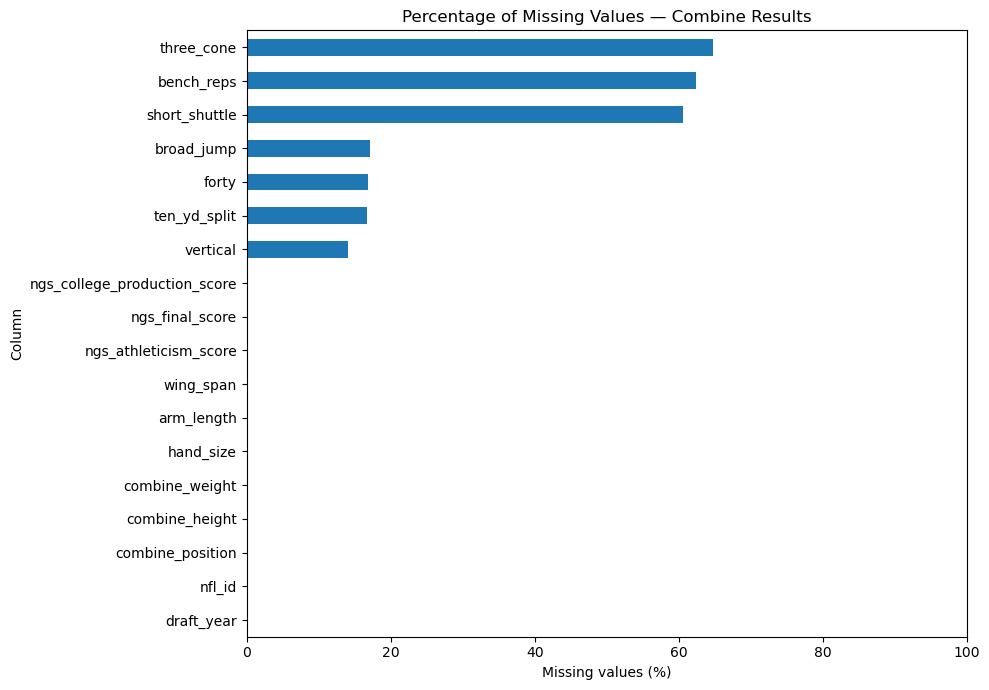

In [10]:
#Plot missing value percent from combine csv

import matplotlib.pyplot as plt

missing_pct = combine.isnull().mean().mul(100).sort_values()

missing_pct.plot(kind="barh", figsize=(10, 7))

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Percentage of Missing Values — Combine Results")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


In [11]:
#For all the drills there are missing values, we must investiagte if there is a trend of a particular position skipping a particular drill

drills = [
    "ten_yd_split",
    "forty",
    "vertical",
    "broad_jump",
    "three_cone",
    "short_shuttle",
    "bench_reps",
]

missing_by_position = (
    combine.groupby("combine_position")[drills]
    .agg(lambda col: col.isna().mean() * 100)
    .round(1)
)

missing_by_position


,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps
combine_position,,,,,,,
DB,14.8,14.8,13.9,19.7,79.5,73.0,63.1
DL,20.3,20.3,13.6,17.8,63.6,61.0,54.2
OL,20.7,21.5,17.4,19.0,49.6,47.1,56.2
TE,19.0,19.0,16.7,16.7,57.1,52.4,71.4
WR,9.3,9.3,10.3,11.2,69.2,64.5,73.8


In [12]:
# Some drill inherintely have more players opt to skip, 
# we  can check if there is a significant difference in missing values across different positions for each drill

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

results = []

for drill in drills:
    # Rows = positions; columns = observed vs. missing
    table = pd.crosstab(
        combine["combine_position"],
        combine[drill].isna()
    )

    # Ensure both outcome categories are present
    table = table.reindex(columns=[False, True], fill_value=0)

    chi2, p_value, dof, expected = chi2_contingency(table)

    # Cramer's V: strength of association
    n = table.to_numpy().sum()
    min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    results.append({
        "drill": drill,
        "missing_pct": combine[drill].isna().mean() * 100,
        "chi2": chi2,
        "degrees_of_freedom": dof,
        "p_value": p_value,
        "cramers_v": cramers_v,
    })

results_df = pd.DataFrame(results)

# Correct the seven p-values for multiple testing
results_df["p_value_holm"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df = results_df.sort_values("p_value_holm")

results_df.round(4)


,drill,missing_pct,chi2,degrees_of_freedom,p_value,cramers_v,p_value_holm
4,three_cone,64.7059,25.8653,4,0.0000,0.2252,0.0002
5,short_shuttle,60.5882,18.8918,4,0.0008,0.1925,0.0050
6,bench_reps,62.3529,12.7734,4,0.0124,0.1583,0.0622
0,ten_yd_split,16.6667,7.1576,4,0.1278,0.1185,0.4119
1,forty,16.8627,7.7058,4,0.1030,0.1229,0.4119
2,vertical,14.1176,2.6044,4,0.6260,0.0715,0.9417
3,broad_jump,17.0588,3.5465,4,0.4708,0.0834,0.9417


Three-cone and short shuttle: Missingness is statistically associated with position. We should examine which specific positions differ using the pairwise tests.



Bench press: There is some evidence of an overall difference before multiple-testing correction, but it does not meet our adjusted 5% significance threshold.



Other four drills: We don't have statistically significant evidence that missingness differs by position. That doesn't prove the rates are identical.

In [13]:
#From chi-squared test of independence across groups we see that 
#Pairwise positional comparisons
from itertools import combinations
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

pairwise_results = []
positions = sorted(combine["combine_position"].dropna().unique())

for drill in drills:
    for pos1, pos2 in combinations(positions, 2):
        group1 = combine.loc[combine["combine_position"] == pos1, drill]
        group2 = combine.loc[combine["combine_position"] == pos2, drill]

        missing_counts = [
            group1.isna().sum(),
            group2.isna().sum()
        ]
        sample_sizes = [len(group1), len(group2)]

        _, p_value = proportions_ztest(
            count=missing_counts,
            nobs=sample_sizes
        )

        rate1 = missing_counts[0] / sample_sizes[0]
        rate2 = missing_counts[1] / sample_sizes[1]

        pairwise_results.append({
            "drill": drill,
            "position_1": pos1,
            "position_2": pos2,
            "missing_pct_1": rate1 * 100,
            "missing_pct_2": rate2 * 100,
            "difference_pp": (rate1 - rate2) * 100,
            "p_value": p_value
        })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df["p_value_holm"] = multipletests(
    pairwise_df["p_value"],
    method="holm"
)[1]

pairwise_df["significant"] = pairwise_df["p_value_holm"] < 0.05

In [14]:
#Results
significant_pairs = (
    pairwise_df.loc[pairwise_df["significant"]]
    .sort_values("p_value_holm")
)

display(significant_pairs.round(3))

,drill,position_1,position_2,missing_pct_1,missing_pct_2,difference_pp,p_value,p_value_holm,significant
41,three_cone,DB,OL,79.508,49.587,29.921,0.0,0.000,True
51,short_shuttle,DB,OL,72.951,47.107,25.843,0.0,0.003,True


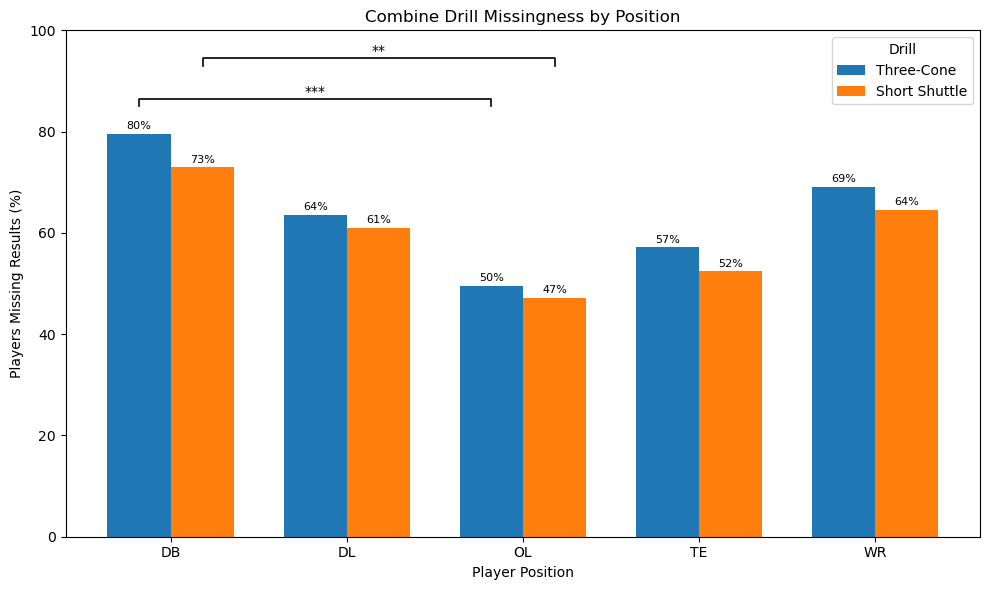

In [19]:
import matplotlib.pyplot as plt
import numpy as np

selected_drills = ["three_cone", "short_shuttle"]

plot_data = (
    combine.groupby("combine_position")[selected_drills]
    .agg(lambda col: col.isna().mean() * 100)
)

plot_data.columns = ["Three-Cone", "Short Shuttle"]

fig, ax = plt.subplots(figsize=(10, 6))

positions = plot_data.index.tolist()
x = np.arange(len(positions))
width = 0.36

bars1 = ax.bar(
    x - width / 2,
    plot_data["Three-Cone"],
    width,
    label="Three-Cone"
)

bars2 = ax.bar(
    x + width / 2,
    plot_data["Short Shuttle"],
    width,
    label="Short Shuttle"
)

ax.set_title("Combine Drill Missingness by Position")
ax.set_xlabel("Player Position")
ax.set_ylabel("Players Missing Results (%)")
ax.set_xticks(x)
ax.set_xticklabels(positions)
ax.set_ylim(0, 100)
ax.legend(title="Drill")

# Annotate each bar with its missingness percentage
ax.bar_label(bars1, fmt="%.0f%%", padding=2, fontsize=8)
ax.bar_label(bars2, fmt="%.0f%%", padding=2, fontsize=8)

# Significant DB vs OL comparisons
def add_bracket(ax, x1, x2, y, label, h=1.5):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        color="black",
        linewidth=1.2
    )
    ax.text(
        (x1 + x2) / 2,
        y + h,
        label,
        ha="center",
        va="bottom"
    )

db_idx = positions.index("DB")
ol_idx = positions.index("OL")

# Bar centers within each position group
add_bracket(
    ax,
    db_idx - width / 2,
    ol_idx - width / 2,
    85,
    "***"
)

add_bracket(
    ax,
    db_idx + width / 2,
    ol_idx + width / 2,
    93,
    "**"
)

plt.tight_layout()
plt.show()

Missing combine results were significantly associated with player position for the three-cone and short-shuttle drills. Defensive backs had higher missingness rates than offensive linemen for both the three-cone (79.5% vs. 49.6%, adjusted p < 0.001) and short shuttle (73.0% vs. 47.1%, adjusted p = 0.003), with both differences remaining significant after Holm correction across 70 pairwise comparisons. These findings suggest that combine data missingness may be position-dependent, although the data alone cannot establish whether players intentionally skipped these drills.

In [20]:
#Check for duplicates
print(combine.duplicated().sum())
print(combine["nfl_id"].duplicated().sum())
print(combine.duplicated(["nfl_id", "draft_year"]).sum())


0
0
0


There are no duplicate entries in the combine csv

In [21]:
#Check for suspicous measurement values
combine.describe().round(2)

,draft_year,nfl_id,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
count,510.00,510.00,510.00,510.00,510.00,510.00,510.00,425.00,424.00,438.00,423.00,180.00,201.00,192.00,510.00,509.00,509.00
mean,2024.03,57331.32,74.58,248.38,9.57,32.41,78.47,1.63,4.73,33.81,118.15,7.31,4.47,21.72,72.45,67.48,70.33
std,0.81,979.51,2.63,53.25,0.60,1.42,3.27,0.12,0.31,4.14,9.06,0.39,0.25,5.72,10.61,8.32,7.53
min,2023.00,55867.00,68.12,154.00,8.00,28.50,69.00,1.46,4.28,23.00,93.00,6.57,3.93,8.00,51.00,50.00,52.00
25%,2023.00,56273.50,72.62,198.00,9.12,31.38,76.25,1.54,4.47,31.00,111.00,7.00,4.28,17.00,65.00,61.00,65.00
50%,2024.00,57290.00,75.00,245.50,9.50,32.38,78.50,1.59,4.62,34.00,120.00,7.29,4.45,22.00,73.00,66.00,70.00
75%,2025.00,58302.75,76.50,304.00,10.00,33.50,80.84,1.74,5.01,37.00,125.00,7.62,4.68,26.00,80.00,73.00,75.00
max,2025.00,59278.00,80.62,374.00,11.62,36.88,88.25,1.96,5.48,44.00,138.00,8.19,5.03,39.00,99.00,99.00,94.00


In [22]:
#Check extreme values
combine.loc[
    combine["forty"].isin([
        combine["forty"].min(),
        combine["forty"].max()
    ]),
    ["nfl_id", "draft_year", "combine_position", "forty"]
]

,nfl_id,draft_year,combine_position,forty
123,56450,2023,OL,5.48
152,56344,2023,OL,5.48
463,58232,2025,DB,4.28


All these values are valid, the 40 yard dash by the db is valid, and o linemen run slow sometimes.

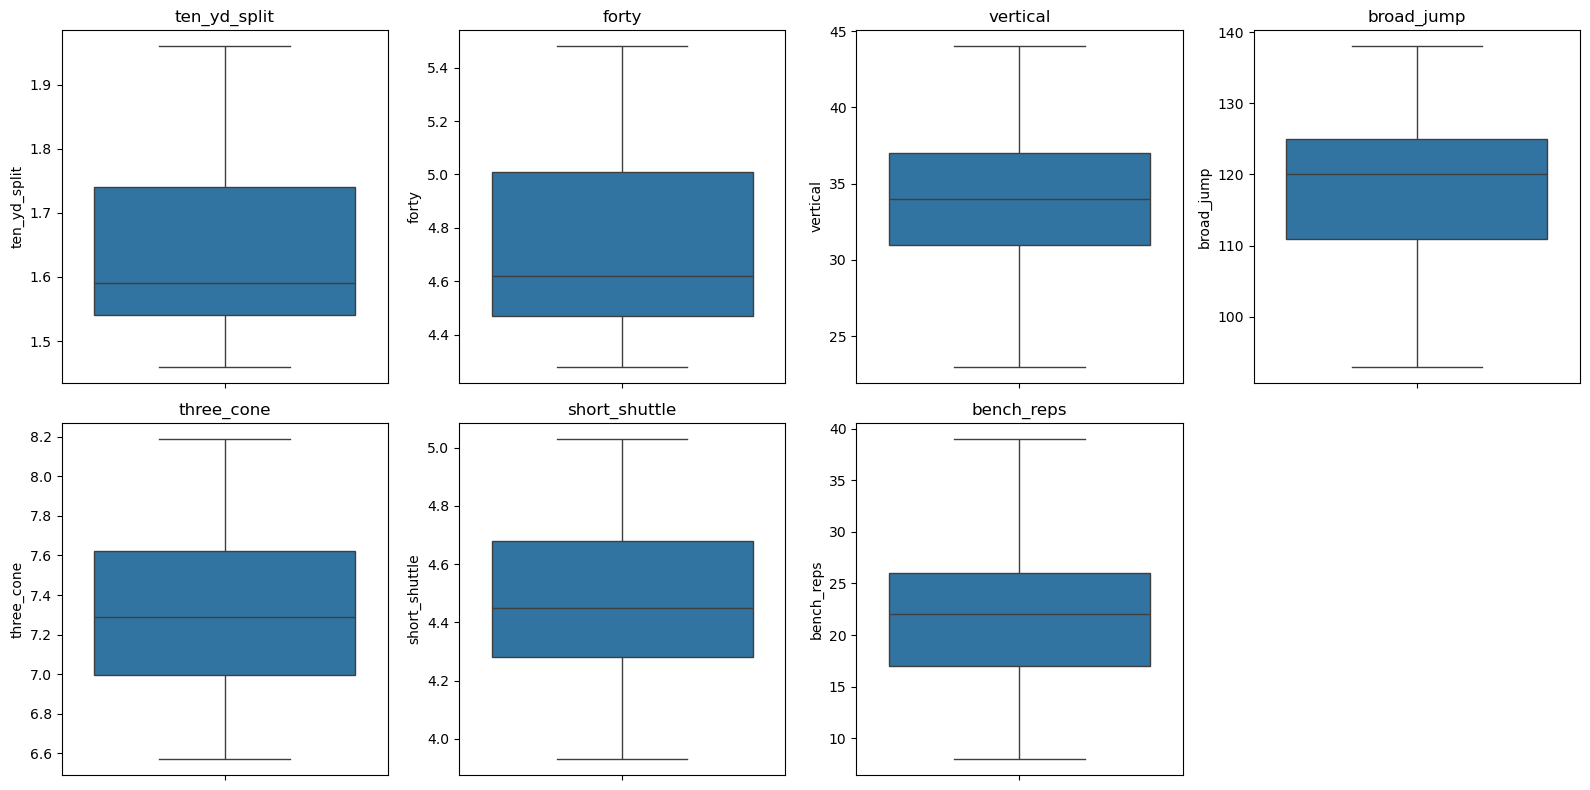

In [23]:
#Check for outliers
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, drill in zip(axes.flat, drills):
    sns.boxplot(data=combine, y=drill, ax=ax)
    ax.set_title(drill)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()


From a quick obsevation there is no outliers flagging any potetnial problems.


### Moving on the combine_tracking.csv

Check the general strcuture of the data

In [25]:
combine_tracking = pd.read_csv(RAW_DATA_DIR / "combine_tracking.csv")

combine_tracking.shape

(463189, 14)

In [27]:
combine_tracking.head()


,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [28]:
combine_tracking.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463189 entries, 0 to 463188
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   draft_year   463189 non-null  int64  
 1   event_id     463189 non-null  object 
 2   nfl_id       463189 non-null  int64  
 3   entity_type  463189 non-null  object 
 4   time         463189 non-null  object 
 5   drill_type   463189 non-null  object 
 6   drill_name   463189 non-null  object 
 7   attempt      463189 non-null  int64  
 8   x            463189 non-null  float64
 9   y            463189 non-null  float64
 10  s            463189 non-null  float64
 11  a            463189 non-null  float64
 12  dis          463189 non-null  float64
 13  dir          463189 non-null  float64
dtypes: float64(6), int64(3), object(5)
memory usage: 49.5+ MB


The tracking combine data measures in 0.1 second increments, ie 10hz for each player during the drill. the first recording is the start of the drill and the last measurement is the very end of the timer of the drill.

In [29]:
combine_tracking["drill_type"].value_counts()
combine_tracking["drill_name"].value_counts()

drill_name
FORTY_YARD_DASH                                 41500
GAUNTLET_DRILL                                  38228
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION    21569
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE          18087
THREE_CONE_DRILL                                15951
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION     12845
OVER_SHOULDER_ADJUST                            12149
LINE_DRILL                                      11895
FOUR_BAG_AGILITY_DRILL                          11709
SHORT_SHUTTLE                                   11690
PASS_RUSH_DROP                                  10752
POST_CORNER_ROUTE_RIGHT                         10517
PASS_RUSH_DRILL                                 10285
W_DRILL                                         10214
DAGGER_ROUTE_LEFT                                9917
GO_ROUTE_RIGHT                                   9843
SLOT_SAIL_ROUTE_RIGHT                            9524
TERYL_AUSTIN_DRILL_2                             9514
BOX_DRILL        

In [30]:
#Check player count and events per drill
drill_summary = (
    combine_tracking.groupby("drill_name")
    .agg(
        players=("nfl_id", "nunique"),
        events=("event_id", "nunique"),
        observations=("nfl_id", "size")
    )
    .sort_values("players", ascending=False)
)

drill_summary

,players,events,observations
drill_name,,,
FORTY_YARD_DASH,418,793,41500
GAUNTLET_DRILL,267,404,38228
SHORT_SHUTTLE,170,223,11690
THREE_CONE_DRILL,160,203,15951
OVER_SHOULDER_ADJUST,130,135,12149
BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL,122,124,8422
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,122,241,21569
BOX_DRILL,122,125,9439
W_DRILL,121,124,10214


Not every player does every drill


In [31]:
#Check overlap from combine results and tracking data
combine_ids = set(combine["nfl_id"])
tracking_ids = set(combine_tracking["nfl_id"])

print("Combine players:", len(combine_ids))
print("Tracking players:", len(tracking_ids))
print("Players in both:", len(combine_ids & tracking_ids))
print("Combine only:", len(combine_ids - tracking_ids))
print("Tracking only:", len(tracking_ids - combine_ids))


Combine players: 510
Tracking players: 510
Players in both: 510
Combine only: 0
Tracking only: 0


There is a perfect match between the two datasets by playerid

In [32]:
drill_pairs = {
    "forty": "FORTY_YARD_DASH",
    "three_cone": "THREE_CONE_DRILL",
    "short_shuttle": "SHORT_SHUTTLE"
}

coverage = []

for measurement, drill in drill_pairs.items():
    measured_ids = set(combine.loc[combine[measurement].notna(), "nfl_id"])
    tracked_ids = set(combine_tracking.loc[combine_tracking["drill_name"] == drill, "nfl_id"])

    coverage.append({
        "drill": drill,
        "measured": len(measured_ids),
        "tracked": len(tracked_ids),
        "both": len(measured_ids & tracked_ids),
        "measured_only": len(measured_ids - tracked_ids),
        "tracked_only": len(tracked_ids - measured_ids)
    })

pd.DataFrame(coverage)

,drill,measured,tracked,both,measured_only,tracked_only
0,FORTY_YARD_DASH,424,418,418,6,0
1,THREE_CONE_DRILL,180,160,150,30,10
2,SHORT_SHUTTLE,201,170,160,41,10


While there is perfect overlap between datasets some players still did not participate in all activities. 

40 yard dash has 98.6 percent coverage
three-cone has 83.3 percent coverage
short shuttle has 79.6 percent coverage 


In [33]:
#Check what is a unique tracking event
event_structure = combine_tracking.groupby("event_id").agg(
    players=("nfl_id", "nunique"),
    drills=("drill_name", "nunique"),
    attempts=("attempt", "nunique")
)

event_structure.describe()

,players,drills,attempts
count,6310.0,6310.0,6310.0
mean,1.0,1.0,1.0
std,0.0,0.0,0.0
min,1.0,1.0,1.0
25%,1.0,1.0,1.0
50%,1.0,1.0,1.0
75%,1.0,1.0,1.0
max,1.0,1.0,1.0


Heirarchy 510 players -> 6,310 drill events total -> 463,189 tracking obersevations

In [ ]:
#Check how timestamp data is imputed
#convert the timestamps 
combine_tracking["time"] = pd.to_datetime(combine_tracking["time"])

In [35]:
#Check the interval between observations
tracking_sorted = combine_tracking.sort_values(["event_id", "time"]).copy()

tracking_sorted["dt"] = (
    tracking_sorted.groupby("event_id")["time"]
    .diff()
    .dt.total_seconds()
)

tracking_sorted["dt"].describe()


count    456879.000000
mean          0.092975
std           0.025557
min           0.000000
25%           0.100000
50%           0.100000
75%           0.100000
max           0.100000
Name: dt, dtype: float64

### The tracking data is 10hz(one every 0.1 seconds)
The variation occurs due to different ending recordings

In [36]:
#How many are zero vs 0.1
tracking_sorted["dt"].value_counts().sort_index()

dt
0.0     32095
0.1    424784
Name: count, dtype: int64

In [37]:
#Check for duplicates
combine_tracking.duplicated().sum()

0

no duplicates

In [38]:
duplicate_times = combine_tracking[
    combine_tracking.duplicated(["event_id", "time"], keep=False)
]

duplicate_times.sort_values(["event_id", "time"]).head(20)

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
142676,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.200,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.225789,23.279475,0.654606,2.028745,0.003011,159.655843
142745,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.200,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.338374,23.570836,0.170420,0.063381,0.000267,194.447420
142677,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.300,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.248583,23.207858,0.869065,2.352696,0.005155,158.848827
142746,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.300,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.334381,23.554161,0.172550,0.061234,0.000279,192.491013
142678,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.400,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.261790,23.085225,1.173742,2.670111,0.015040,162.034010
142747,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.400,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.330905,23.537150,0.174755,0.059142,0.000290,190.643340
142679,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.500,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.304021,22.958316,1.453305,2.893052,0.016205,159.101506
142748,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.500,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.327922,23.519816,0.177016,0.057103,0.000301,188.899125
142680,2025,20250228100500_1740789896177_000,58407,PLAYER,2025-03-01 00:44:50.600,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.354266,22.811946,1.785264,3.633536,0.021572,152.304800
142749,2025,20250228100500_1740789896177_000,58407,BALL,2025-03-01 00:44:50.600,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,24.325422,23.502177,0.179313,0.055118,0.000311,187.252883


### There is not just player tracking data but also ball tracking data

Heirarchy player -> Drill even -> Player tracking and Ball tracking -> timestampled observations

In [39]:
combine_tracking["entity_type"].value_counts()

entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64

There is 93.1 percent of the observations are from player data the rest are from ball tracking

In [40]:
combine_tracking.duplicated(
    ["event_id", "entity_type", "time"]
).sum()

0

In [41]:
tracking_sorted = combine_tracking.sort_values(
    ["event_id", "entity_type", "time"]
).copy()

tracking_sorted["dt"] = (
    tracking_sorted.groupby(["event_id", "entity_type"])["time"]
    .diff()
    .dt.total_seconds()
)

tracking_sorted["dt"].value_counts().sort_index()

dt
0.1    456328
Name: count, dtype: int64

All oberservations are exactly 0.1 seconds apart


In [43]:
#Inspecting the numeric data structure
combine_tracking.groupby("entity_type")[
    ["x", "y", "s", "a", "dis", "dir"]
].describe().round(3)

x                                                  \
                count    mean     std     min     25%     50%     75%   
entity_type                                                             
BALL          32095.0  32.895  14.406  13.583  22.242  27.478  40.912   
PLAYER       431094.0  45.109  17.239   1.300  36.231  44.667  48.433   

                             y          ...    dis               dir           \
                 max     count    mean  ...    75%     max     count     mean   
entity_type                             ...                                     
BALL          81.881   32095.0  25.190  ...  1.999  45.285   32095.0  165.409   
PLAYER       103.900  431094.0  23.954  ...  0.490   1.440  431094.0  148.496   

                                                               
                std    min     25%      50%      75%      max  
entity_type                                                    
BALL         92.109  0.016  84.511  127.477  265.313  359.902  
PLAYER       96.632  0.000  88.142  109.552  226.378  360.000  

[2 rows x 48 columns]

In [44]:
combine_tracking.groupby("entity_type")[
    ["s", "a", "dis"]
].agg(["min", "mean", "median", "std", "max"]).round(3)

s                                 a                       \
               min   mean median    std     max  min   mean median    std   
entity_type                                                                 
BALL         0.006  7.818  4.221  7.644  25.794  0.0  2.564  1.823  2.913   
PLAYER       0.000  4.931  4.977  2.843  11.854  0.0  2.832  2.566  1.847   

                     dis                               
                max  min   mean median    std     max  
entity_type                                            
BALL         44.607  0.0  1.074  0.171  1.829  45.285  
PLAYER       10.718  0.0  0.299  0.218  0.284   1.440

In [45]:
combine_tracking.nlargest(10, "dis")[
    ["event_id", "entity_type", "drill_name", "time", "s", "a", "dis"]
]

,event_id,entity_type,drill_name,time,s,a,dis
118230,20250301100700_1740866676846_000,BALL,COMEBACK_ROUTE_RIGHT,2025-03-01 22:04:30.700,2.522485,0.935003,45.285317
73363,20250301100800_1740874616438_000,BALL,CIRCUS_ROUTE_LEFT,2025-03-02 00:16:51.600,22.436798,0.088770,35.110196
135751,20250301100700_1740866664422_000,BALL,COMEBACK_ROUTE_RIGHT,2025-03-01 22:04:19.300,1.629627,2.867560,34.837891
71139,20250301100700_1740864795627_000,BALL,SPEED_OUT_ROUTE_LEFT,2025-03-01 21:33:14.000,4.228181,1.818115,34.018407
100318,20250301100800_1740874486084_000,BALL,DAGGER_ROUTE_LEFT,2025-03-02 00:14:43.200,2.686012,4.182231,32.248844
93175,20250301100700_1740865154761_000,BALL,DAGGER_ROUTE_LEFT,2025-03-01 21:39:12.700,2.862532,3.027289,32.121681
47380,20250301100700_1740865133934_000,BALL,DAGGER_ROUTE_LEFT,2025-03-01 21:38:51.100,2.710268,0.543411,31.781334
139799,20250228100500_1740792073446_000,BALL,WHEEL_ROUTE_LEFT,2025-03-01 01:21:11.600,3.352135,8.123480,31.152561
174231,20250301100800_1740876046245_000,BALL,COMEBACK_ROUTE_RIGHT,2025-03-02 00:40:44.100,3.727615,0.367907,29.890681
134941,20250301100700_1740866963975_000,BALL,POST_CORNER_ROUTE_RIGHT,2025-03-01 22:09:21.900,2.522970,7.457391,28.026221


We can calculate actual cordinate displacement


In [46]:
event = combine_tracking.loc[
    combine_tracking["dis"].idxmax(), "event_id"
]

ball_event = combine_tracking[
    (combine_tracking["event_id"] == event) &
    (combine_tracking["entity_type"] == "BALL")
].sort_values("time").copy()

ball_event["calculated_dis"] = np.sqrt(
    ball_event["x"].diff()**2 +
    ball_event["y"].diff()**2
)

ball_event.nlargest(10, "dis")[
    ["time", "x", "y", "s", "dis", "calculated_dis"]
]

,time,x,y,s,dis,calculated_dis
118230,2025-03-01 22:04:30.700,44.899389,-5.240794,2.522485,45.285317,7.506777
118215,2025-03-01 22:04:29.200,19.362591,24.506416,23.697070,6.043221,2.907547
118216,2025-03-01 22:04:29.300,20.940750,22.733800,23.659309,4.009519,2.373342
118217,2025-03-01 22:04:29.400,22.524651,20.973347,23.593516,3.987330,2.368108
118218,2025-03-01 22:04:29.500,24.111387,19.227423,23.499723,3.953579,2.359233
118219,2025-03-01 22:04:29.600,25.694633,17.497100,23.381783,3.904812,2.345355
118220,2025-03-01 22:04:29.700,27.283572,15.786851,23.240196,3.863880,2.334454
118221,2025-03-01 22:04:29.800,28.866074,14.095300,23.077957,3.802483,2.316389
118222,2025-03-01 22:04:29.900,30.446030,12.425046,22.897682,3.743529,2.299132
118223,2025-03-01 22:04:30.000,32.021571,10.776725,22.702621,3.680198,2.280196


In [47]:
player_tracking = tracking_sorted[
    tracking_sorted["entity_type"] == "PLAYER"
].copy()

player_tracking["calculated_speed"] = (
    np.sqrt(
        player_tracking.groupby("event_id")["x"].diff()**2 +
        player_tracking.groupby("event_id")["y"].diff()**2
    ) / 0.1
)

player_tracking[["s", "calculated_speed"]].describe().round(3)

,s,calculated_speed
count,431094.000,424784.000
mean,4.931,4.980
std,2.843,2.816
min,0.000,0.000
25%,2.440,2.539
50%,4.977,5.011
75%,7.296,7.333
max,11.854,12.005


In [48]:
speed_comparison = player_tracking[
    ["s", "calculated_speed"]
].dropna().copy()

speed_comparison["absolute_error"] = (
    speed_comparison["s"] -
    speed_comparison["calculated_speed"]
).abs()

print("Correlation:", speed_comparison["s"].corr(speed_comparison["calculated_speed"]))
print("Mean absolute error:", speed_comparison["absolute_error"].mean())
print("Median absolute error:", speed_comparison["absolute_error"].median())
print("95th percentile error:", speed_comparison["absolute_error"].quantile(0.95))

Correlation: 0.9982817597059045
Mean absolute error: 0.12537664039950439
Median absolute error: 0.10000000300000189
95th percentile error: 0.32408594537428204


Our calculated speeds from the x,y cordinates matches the recorded speed extremely well

In [49]:
#looking at the duration of the drill times
event_durations = (
    combine_tracking[combine_tracking["entity_type"] == "PLAYER"]
    .groupby(["event_id", "drill_name"])
    .agg(
        start=("time", "min"),
        end=("time", "max"),
        frames=("time", "size")
    )
    .reset_index()
)

event_durations["duration"] = (
    event_durations["end"] - event_durations["start"]
).dt.total_seconds()

event_durations["duration"].describe()

count    6310.000000
mean        6.731918
std         2.416640
min         0.900000
25%         5.000000
50%         6.200000
75%         7.900000
max        20.800000
Name: duration, dtype: float64

The drills range from 0.9 seconds long to 20.8 seconds long. We can then look at the duration of each drill individually


In [50]:
# Individual drill durations
duration_summary = (
    event_durations.groupby("drill_name")["duration"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

duration_summary

,count,mean,std,min,median,max
drill_name,,,,,,
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,120,14.97,2.47,9.5,15.30,20.1
FOUR_BAG_SHUFFLE_DRILL,3,12.07,0.78,11.2,12.30,12.7
WAVE_DRILL,4,11.82,0.58,11.2,11.75,12.6
SHORT_ZONE_BREAK_FLAT_WHEEL,20,11.77,1.35,10.1,11.40,15.1
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION,112,11.37,1.87,4.4,11.55,15.2
BACK_PEDAL_AND_REACT,62,10.39,0.79,8.5,10.50,12.3
FOUR_BAG_AGILITY_DRILL,112,10.35,1.42,3.2,10.45,14.9
SHUFFLE_SPRINT_AND_COD_DRILL,4,9.55,0.44,9.0,9.60,10.0
GAUNTLET_DRILL,404,9.36,0.92,7.1,9.15,12.4


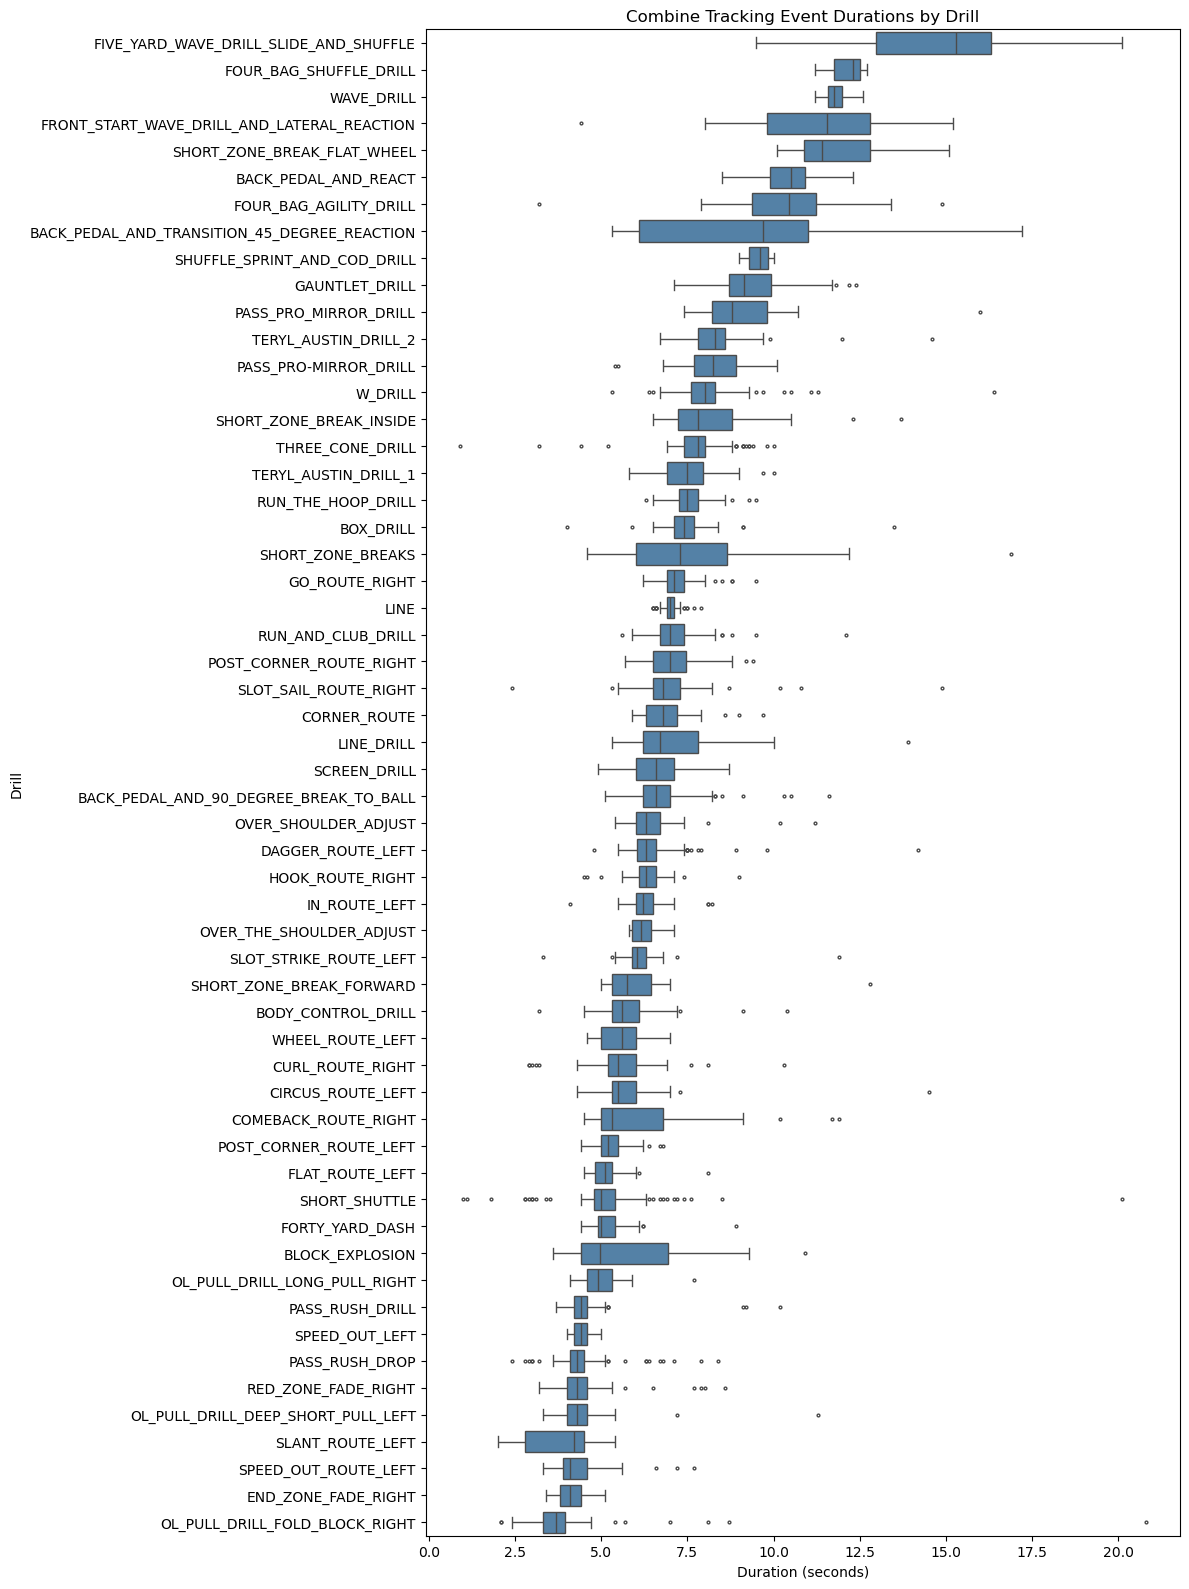

In [51]:
#Quick plot
plt.figure(figsize=(12, 16))

order = (
    event_durations.groupby("drill_name")["duration"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=event_durations,
    x="duration",
    y="drill_name",
    order=order,
    color="steelblue",
    fliersize=2
)

plt.title("Combine Tracking Event Durations by Drill")
plt.xlabel("Duration (seconds)")
plt.ylabel("Drill")
plt.tight_layout()
plt.show()

Some events are unusually long and some are unusually short

In [52]:
event_durations[
    (event_durations["duration"] < 2) |
    (event_durations["duration"] > 18)
][["event_id", "drill_name", "frames", "duration"]].sort_values("duration")

,event_id,drill_name,frames,duration
2149,20240303101000_1709502890626_000,THREE_CONE_DRILL,10,0.9
745,20240301100300_1709331900370_000,SHORT_SHUTTLE,11,1.0
3328,20250228100500_1740793859122_000,SHORT_SHUTTLE,12,1.1
4336,20250302101000_1740950071992_000,SHORT_SHUTTLE,19,1.8
1982,20240303101000_1709499766983_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,182,18.1
1972,20240303101000_1709499560263_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,185,18.4
1961,20240303101000_1709499343798_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,187,18.6
5100,6406869fe3d8e72dcdd1b95a-2023,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,187,18.6
1966,20240303101000_1709499445904_000,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,187,18.6
5269,64068a12e3d8e72dcddcb05e-2023,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,189,18.8


Some of these observations are troublesome. There are some three conde drills that end abruptly and must have some reasoning to support their inclusion. The drill may have been ended early or stopped via rules breaking. There is also some worriesome observations that went extremely long compared to the median drill times for short shuttle and OL pull/ fold block

### Moving on to the Games.csv


In [53]:
games = pd.read_csv(RAW_DATA_DIR / "games.csv")

print(games.shape)
games.info()

(1002, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   game_id            1002 non-null   int64 
 1   game_key           1002 non-null   int64 
 2   season             1002 non-null   int64 
 3   season_type        1002 non-null   object
 4   week               1002 non-null   int64 
 5   home_team_abbr     1002 non-null   object
 6   visitor_team_abbr  1002 non-null   object
dtypes: int64(4), object(3)
memory usage: 54.9+ KB


In [54]:
games.head()

,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


In [55]:
print(games["season"].value_counts().sort_index())
print(games["season_type"].value_counts())

print("Duplicate game IDs:", games["game_id"].duplicated().sum())
print("Duplicate game keys:", games["game_key"].duplicated().sum())

season
2023    334
2024    334
2025    334
Name: count, dtype: int64
season_type
REG     816
PRE     147
POST     39
Name: count, dtype: int64
Duplicate game IDs: 0
Duplicate game keys: 0


Dataset covers the three seasons for the players immediately following their respective drafts

In [56]:
pd.crosstab(games["season"], games["season_type"])

season_type,POST,PRE,REG
season,,,
2023,13,49,272
2024,13,49,272
2025,13,49,272


In [57]:
games.groupby(["season", "season_type", "week"]).size().unstack(
    ["season", "season_type"]
).fillna(0).astype(int)

season      2023         2024         2025        
season_type POST PRE REG POST PRE REG POST PRE REG
week                                              
0              0   1   0    0   1   0    0   1   0
1              0  16  16    0  16  16    0  16  16
2              0  16  16    0  16  16    0  16  16
3              0  16  16    0  16  16    0  16  16
4              0   0  16    0   0  16    0   0  16
5              0   0  14    0   0  14    0   0  14
6              0   0  15    0   0  14    0   0  15
7              0   0  13    0   0  15    0   0  15
8              0   0  16    0   0  16    0   0  13
9              0   0  14    0   0  15    0   0  14
10             0   0  14    0   0  14    0   0  14
11             0   0  14    0   0  14    0   0  15
12             0   0  16    0   0  13    0   0  14
13             0   0  13    0   0  16    0   0  16
14             0   0  15    0   0  13    0   0  14
15             0   0  16    0   0  16    0   0  16
16             0   0  16    0   0  16    0   0  16
17             0   0  16    0   0  16    0   0  16
18             0   0  16    0   0  16    0   0  16
19             6   0   0    6   0   0    6   0   0
20             4   0   0    4   0   0    4   0   0
21             2   0   0    2   0   0    2   0   0
23             1   0   0    1   0   0    1   0   0

In [58]:
#verify team identifiers
teams = set(games["home_team_abbr"]) | set(games["visitor_team_abbr"])

print("Unique teams:", len(teams))
print("Teams:", sorted(teams))
print("Same home and away team:",
      (games["home_team_abbr"] == games["visitor_team_abbr"]).sum())

Unique teams: 33
Teams: ['ARI', 'ATL', 'BAL', 'BUF', 'CAR', 'CHI', 'CIN', 'CLE', 'DAL', 'DEN', 'DET', 'GB', 'HOU', 'IND', 'JAX', 'KC', 'LA', 'LAC', 'LAR', 'LV', 'MIA', 'MIN', 'NE', 'NO', 'NYG', 'NYJ', 'PHI', 'PIT', 'SEA', 'SF', 'TB', 'TEN', 'WAS']
Same home and away team: 0


La and LAR both refer to the LA Rams and must be fixed

In [59]:
games[
    games["home_team_abbr"].isin(["LA", "LAR"]) |
    games["visitor_team_abbr"].isin(["LA", "LAR"])
].groupby(
    ["season", "season_type", "home_team_abbr", "visitor_team_abbr"]
).size()

season  season_type  home_team_abbr  visitor_team_abbr
2023    POST         DET             LA                   1
        PRE          DEN             LA                   1
                     LA              LAC                  1
                                     LV                   1
        REG          ARI             LA                   1
                                                         ..
2025    REG          LAR             TB                   1
                     PHI             LAR                  1
                     SEA             LAR                  1
                     SF              LAR                  1
                     TEN             LAR                  1
Length: 66, dtype: int64

In [60]:
for season in sorted(games["season"].unique()):
    subset = games[games["season"] == season]
    print(f"\nSeason {season}")
    print("LA:", subset[["home_team_abbr", "visitor_team_abbr"]].eq("LA").sum().sum())
    print("LAR:", subset[["home_team_abbr", "visitor_team_abbr"]].eq("LAR").sum().sum())


Season 2023
LA: 21
LAR: 0

Season 2024
LA: 22
LAR: 0

Season 2025
LA: 0
LAR: 23


This inconsitency is attributed to the Rams moving to LAR in 2025

### Judgment call
We should standardize LA to LAR

In [61]:
games_clean = games.copy()

games_clean["home_team_abbr"] = games_clean["home_team_abbr"].replace("LA", "LAR")
games_clean["visitor_team_abbr"] = games_clean["visitor_team_abbr"].replace("LA", "LAR")

teams_clean = set(games_clean["home_team_abbr"]) | set(games_clean["visitor_team_abbr"])

print("Unique teams:", len(teams_clean))
print("Duplicate game IDs:", games_clean["game_id"].duplicated().sum())
print("Same home and away team:",
      (games_clean["home_team_abbr"] == games_clean["visitor_team_abbr"]).sum())

Unique teams: 32
Duplicate game IDs: 0
Same home and away team: 0


### Moving on to Game tracking 2023


In [62]:
game_tracking_2023 = pd.read_csv(
    RAW_DATA_DIR / "game_tracking_2023.csv"
)

print("Shape:", game_tracking_2023.shape)
print("\nColumn information:")
game_tracking_2023.info()

display(game_tracking_2023.head())

Shape: (3665443, 12)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3665443 entries, 0 to 3665442
Data columns (total 12 columns):
 #   Column   Dtype  
---  ------   -----  
 0   game_id  int64  
 1   play_id  int64  
 2   nfl_id   int64  
 3   time     object 
 4   x        float64
 5   y        float64
 6   s        float64
 7   a        float64
 8   dis      float64
 9   o        float64
 10  dir      float64
 11  event    object 
dtypes: float64(7), int64(3), object(2)
memory usage: 335.6+ MB


,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2024010707,570,56450,2024-01-07T21:46:07.700,42.17,25.29,0.0,0.0,0.0,290.97,213.26,NaN
1,2024010707,570,56450,2024-01-07T21:46:07.800,42.17,25.29,0.0,0.0,0.0,290.97,210.36,NaN
2,2024010707,570,56450,2024-01-07T21:46:07.900,42.18,25.29,0.0,0.0,0.0,290.97,205.45,NaN
3,2024010707,570,56450,2024-01-07T21:46:08.000,42.18,25.29,0.0,0.0,0.0,290.97,200.73,NaN
4,2024010707,570,56450,2024-01-07T21:46:08.100,42.18,25.29,0.0,0.0,0.0,290.97,199.27,NaN


Very large data set with approx 3.66 million observations

In [63]:
#Check for missing values and coverage
print("Unique games:", game_tracking_2023["game_id"].nunique())
print("Unique plays:", game_tracking_2023[["game_id", "play_id"]].drop_duplicates().shape[0])
print("Unique players:", game_tracking_2023["nfl_id"].nunique())

print("\nMissing values:")
display(game_tracking_2023.isna().sum())

print("\nExact duplicate rows:", game_tracking_2023.duplicated().sum())

Unique games: 333
Unique plays: 31690
Unique players: 156

Missing values:


game_id          0
play_id          0
nfl_id           0
time             0
x                0
y                0
s                0
a                0
dis              0
o                0
dir              0
event      3422066
dtype: int64


Exact duplicate rows: 0


This dataset tracks a small subset of NFL players (156), only those present in the 2023 NFL Draft

In [64]:
#Game coverage and player distribution
games_2023 = set(games.loc[games["season"] == 2023, "game_id"])
tracked_games = set(game_tracking_2023["game_id"])

print("Games without tracking:", games_2023 - tracked_games)
print("Tracked games not in games.csv:", tracked_games - games_2023)

print("\nTracking observations per player:")
display(
    game_tracking_2023.groupby("nfl_id")
    .size()
    .describe()
)

Games without tracking: {2023100108}
Tracked games not in games.csv: set()

Tracking observations per player:


count      156.000000
mean     23496.429487
std      22911.160245
min        115.000000
25%       6431.000000
50%      14437.500000
75%      36744.000000
max      98097.000000
dtype: float64

Not all players play equal amounts once they are in the professionals


In [65]:
#check overlap with combine data
tracked_players = set(game_tracking_2023["nfl_id"])
combine_players = set(combine["nfl_id"])

print("Tracked players:", len(tracked_players))
print("Combine players:", len(combine_players))
print("Players in both:", len(tracked_players & combine_players))
print("Tracking-only players:", len(tracked_players - combine_players))
print("Combine-only players:", len(combine_players - tracked_players))

Tracked players: 156
Combine players: 510
Players in both: 156
Tracking-only players: 0
Combine-only players: 354


In [66]:
tracked_2023 = combine[
    combine["nfl_id"].isin(game_tracking_2023["nfl_id"])
]

pd.crosstab(
    combine["draft_year"],
    combine["nfl_id"].isin(game_tracking_2023["nfl_id"]),
    rownames=["Draft year"],
    colnames=["Tracked in 2023"]
)

Tracked in 2023,False,True
Draft year,,
2023,4,156
2024,177,0
2025,173,0


In [67]:
print("Unique event types:", game_tracking_2023["event"].nunique())

display(
    game_tracking_2023["event"]
    .value_counts(dropna=False)
)

Unique event types: 44


event
NaN                          3422066
ball_snap                      50813
pass_forward                   31422
tackle                         29011
first_contact                  28345
pass_arrived                   23967
pass_outcome_caught            18845
handoff                        14053
pass_outcome_incomplete        10862
play_action                     8274
out_of_bounds                   6082
autoevent_passinterrupted       4237
run                             2899
qb_sack                         2104
man_in_motion                   1827
line_set                        1610
play_submit                     1264
touchdown                       1174
dropped_pass                     807
pass_outcome_interception        754
pass_outcome_touchdown           646
pass_tipped                      561
fumble                           496
qb_kneel                         493
qb_slide                         419
shift                            397
fumble_offense_recovered        

In [68]:
#Check tracking observation uniqueness
print(
    "Duplicate player-play-timestamp records:",
    game_tracking_2023.duplicated(
        subset=["game_id", "play_id", "nfl_id", "time"]
    ).sum()
)

print("\nMissing values by column:")
display(game_tracking_2023.isna().sum())

print("\nUnique timestamps:", game_tracking_2023["time"].nunique())

Duplicate player-play-timestamp records: 0

Missing values by column:


game_id          0
play_id          0
nfl_id           0
time             0
x                0
y                0
s                0
a                0
dis              0
o                0
dir              0
event      3422066
dtype: int64


Unique timestamps: 2032176


In [69]:
#Tracking frequency
game_tracking_2023["time"] = pd.to_datetime(game_tracking_2023["time"])

tracking_sorted_2023 = game_tracking_2023.sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
)

dt = (
    tracking_sorted_2023
    .groupby(["game_id", "play_id", "nfl_id"])["time"]
    .diff()
    .dt.total_seconds()
)

print("Sampling interval distribution:")
display(dt.value_counts(dropna=False).head(15))

print("\nSampling interval summary:")
display(dt.describe())

Sampling interval distribution:


time
0.1    3614529
NaN      50911
0.2          3
Name: count, dtype: int64


Sampling interval summary:


count    3.614532e+06
mean     1.000001e-01
std      9.110338e-05
min      1.000000e-01
25%      1.000000e-01
50%      1.000000e-01
75%      1.000000e-01
max      2.000000e-01
Name: time, dtype: float64

Just like the combine tracking data the frequency tracking data here is measured at 10hz

In [70]:
tracking_cols = ["x", "y", "s", "a", "dis", "o", "dir"]

game_tracking_2023[tracking_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
x,3665443.0,60.178,24.514,-5.89,40.98,60.29,79.34,126.73
y,3665443.0,26.793,9.697,-7.29,21.04,26.77,32.49,61.24
s,3665443.0,2.531,2.127,0.00,0.81,2.08,3.79,12.67
a,3665443.0,1.636,1.294,0.00,0.65,1.40,2.35,18.33
dis,3665443.0,0.257,0.214,0.00,0.08,0.21,0.38,3.44
o,3665443.0,177.684,100.822,0.00,88.21,177.50,268.08,360.00
dir,3665443.0,179.621,103.362,0.00,89.01,179.83,269.41,360.00


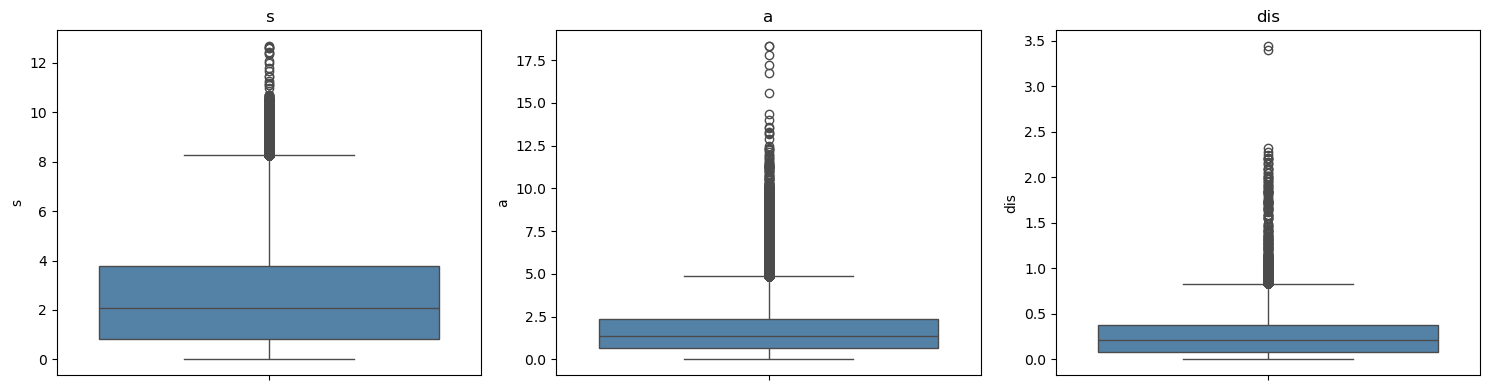

In [71]:
#Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["s", "a", "dis"]):
    sns.boxplot(
        y=game_tracking_2023[col],
        ax=ax,
        color="steelblue"
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [73]:
#Check the observations outside the field
outside_field = (
    (game_tracking_2023["x"] < 0) |
    (game_tracking_2023["x"] > 120) |
    (game_tracking_2023["y"] < 0) |
    (game_tracking_2023["y"] > 53.3)
)

print("Observations outside field:", outside_field.sum())
print("Percentage outside field:", round(outside_field.mean() * 100, 3))

Observations outside field: 14336
Percentage outside field: 0.391


Only a tiny portion of measurements are from outside the playing field which can be attributed to the sensor out of bounds.

In [74]:
tracking_sorted_2023 = game_tracking_2023.sort_values(
    ["game_id", "play_id", "nfl_id", "time"]
).copy()

groups = tracking_sorted_2023.groupby(
    ["game_id", "play_id", "nfl_id"]
)

tracking_sorted_2023["calculated_dis"] = np.sqrt(
    groups["x"].diff()**2 +
    groups["y"].diff()**2
)

dis_comparison = tracking_sorted_2023[
    ["dis", "calculated_dis"]
].dropna().copy()

dis_comparison["absolute_error"] = (
    dis_comparison["dis"] - dis_comparison["calculated_dis"]
).abs()

print("Correlation:", dis_comparison["dis"].corr(dis_comparison["calculated_dis"]))
print("Mean absolute error:", dis_comparison["absolute_error"].mean())
print("95th percentile error:", dis_comparison["absolute_error"].quantile(0.95))

display(dis_comparison.nlargest(10, "absolute_error"))

Correlation: 0.9746138299852448
Mean absolute error: 0.0038421134005024284
95th percentile error: 0.010000000000001563


,dis,calculated_dis,absolute_error
2531452,0.00,40.576566,40.576566
2530320,0.00,39.660944,39.660944
2531486,0.00,39.031302,39.031302
2530364,0.01,38.726411,38.716411
927701,0.00,34.074725,34.074725
927740,0.01,33.590862,33.580862
165841,0.29,1.290620,1.000620
2032482,0.37,1.222865,0.852865
1424536,0.17,0.940851,0.770851
2339605,0.93,0.172627,0.757373


In [75]:
#Six obersvations draw a closer look
tracking_sorted_2023["dis_error"] = (
    tracking_sorted_2023["dis"] -
    tracking_sorted_2023["calculated_dis"]
).abs()

display(
    tracking_sorted_2023.nlargest(10, "dis_error")[
        ["game_id", "play_id", "nfl_id", "time",
         "x", "y", "s", "dis", "calculated_dis", "dis_error"]
    ]
)

,game_id,play_id,nfl_id,time,x,y,s,dis,calculated_dis,dis_error
2531452,2023081151,115,55922,2023-08-11 23:10:44.500,41.38,24.20,0.00,0.00,40.576566,40.576566
2530320,2023081151,93,55922,2023-08-11 23:10:19.900,43.33,24.25,0.00,0.00,39.660944,39.660944
2531486,2023081151,115,55922,2023-08-11 23:10:48.000,63.68,58.02,0.01,0.00,39.031302,39.031302
2530364,2023081151,93,55922,2023-08-11 23:10:24.400,64.10,58.03,0.09,0.01,38.726411,38.716411
927701,2023081151,1836,55922,2023-08-12 00:17:08.000,96.00,30.33,0.00,0.00,34.074725,34.074725
927740,2023081151,1836,55922,2023-08-12 00:17:12.000,77.86,59.03,0.03,0.01,33.590862,33.580862
165841,2023081151,332,55922,2023-08-11 23:19:12.500,32.33,22.29,3.56,0.29,1.290620,1.000620
2032482,2023091708,3978,55888,2023-09-17 22:54:47.800,83.36,12.92,3.56,0.37,1.222865,0.852865
1424536,2023081151,948,55922,2023-08-11 23:42:27.900,83.04,23.93,6.34,0.17,0.940851,0.770851
2339605,2023081151,1649,55922,2023-08-12 00:10:00.700,56.00,24.62,0.17,0.93,0.172627,0.757373


In [76]:
#Anomaly spread
anomalies = tracking_sorted_2023[
    tracking_sorted_2023["dis_error"] > 0.5
]

print("Anomalous observations:", len(anomalies))
print("Percentage of valid comparisons:",
      round(len(anomalies) / len(dis_comparison) * 100, 4))

print("Affected players:", anomalies["nfl_id"].nunique())
print("Affected games:", anomalies["game_id"].nunique())
print("Affected plays:",
      anomalies[["game_id", "play_id"]].drop_duplicates().shape[0])

display(
    anomalies.groupby(["game_id", "nfl_id"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Anomalous observations: 14
Percentage of valid comparisons: 0.0004
Affected players: 2
Affected games: 2
Affected plays: 9


game_id     nfl_id
2023081151  55922     13
2023091708  55888      1
dtype: int64

In [77]:
#Check if there is direct connection between cordinate speed and recorded speed
tracking_sorted_2023["dt"] = (
    tracking_sorted_2023.groupby(
        ["game_id", "play_id", "nfl_id"]
    )["time"].diff().dt.total_seconds()
)

tracking_sorted_2023["calculated_speed"] = (
    tracking_sorted_2023["calculated_dis"] /
    tracking_sorted_2023["dt"]
)

speed_comparison = tracking_sorted_2023[
    ["s", "calculated_speed"]
].replace([np.inf, -np.inf], np.nan).dropna().copy()

speed_comparison["absolute_error"] = (
    speed_comparison["s"] - speed_comparison["calculated_speed"]
).abs()

print("Correlation:", speed_comparison["s"].corr(speed_comparison["calculated_speed"]))
print("Mean absolute error:", speed_comparison["absolute_error"].mean())
print("Median absolute error:", speed_comparison["absolute_error"].median())
print("95th percentile error:", speed_comparison["absolute_error"].quantile(0.95))


Correlation: 0.9812123260457997
Mean absolute error: 0.0922079127691224
Median absolute error: 0.07099202643648539
95th percentile error: 0.23960780543714022


In [78]:
valid_speed = tracking_sorted_2023[
    tracking_sorted_2023["calculated_speed"].notna()
]

clean_speed = valid_speed[
    valid_speed["dis_error"] <= 0.5
]

print("All observations correlation:",
      valid_speed["s"].corr(valid_speed["calculated_speed"]))

print("Without flagged intervals correlation:",
      clean_speed["s"].corr(clean_speed["calculated_speed"]))

print("Without flagged intervals MAE:",
      (clean_speed["s"] - clean_speed["calculated_speed"]).abs().mean())

All observations correlation: 0.9812123260457997
Without flagged intervals correlation: 0.9973232845172773
Without flagged intervals MAE: 0.0917287628688532


The fourteen observations that once removed increase the correlation from 0.9812 to 0.9973


In [79]:
#Check player coverage
player_coverage_2023 = (
    game_tracking_2023.groupby("nfl_id")
    .agg(
        games=("game_id", "nunique"),
        tracking_frames=("time", "size")
    )
)

player_coverage_2023["plays"] = (
    game_tracking_2023.groupby("nfl_id")
    .apply(
        lambda x: x[["game_id", "play_id"]].drop_duplicates().shape[0],
        include_groups=False
    )
)

display(player_coverage_2023.describe().round(2))

,games,tracking_frames,plays
count,156.00,156.00,156.00
mean,11.38,23496.43,326.35
std,6.81,22911.16,321.66
min,1.00,115.00,1.00
25%,4.00,6431.00,91.00
50%,12.00,14437.50,200.50
75%,18.00,36744.00,511.75
max,24.00,98097.00,1383.00


In [80]:
#Player coverage by position
players = pd.read_csv(RAW_DATA_DIR / "players.csv")

coverage_by_position_2023 = player_coverage_2023.reset_index().merge(
    players[["nfl_id", "nfl_position"]],
    on="nfl_id",
    how="left",
    validate="one_to_one"
)

print("Players without position:",
      coverage_by_position_2023["nfl_position"].isna().sum())

display(
    coverage_by_position_2023.groupby("nfl_position")[
        ["games", "plays", "tracking_frames"]
    ].agg(["count", "median", "mean"]).round(1)
)

Players without position: 0


games              plays               tracking_frames           \
             count median  mean count median   mean           count   median   
nfl_position                                                                   
C                7    6.0   6.4     7  172.0  301.4               7  12368.0   
CB              15   10.0   9.9    15  340.0  378.7              15  24925.0   
DE              14   10.5  11.6    14  207.0  266.9              14  14598.5   
DT               8   10.5  11.5     8  215.0  266.5               8  15129.5   
FS               7    4.0   6.9     7  110.0  187.3               7   7841.0   
G               17   12.0  11.5    17  471.0  563.4              17  32020.0   
NT               3    8.0  10.0     3  173.0  166.0               3  12364.0   
OLB             10   15.0  13.2    10  214.5  375.0              10  15570.5   
SS              12   11.5  11.8    12  231.0  347.7              12  16419.0   
T               13    8.0  10.2    13  228.0  527.2              13  15545.0   
TE              12   14.0  12.7    12  110.0  130.6              12   8357.0   
WR              38   16.0  13.1    38  229.0  250.6              38  17500.0   

                       
                 mean  
nfl_position           
C             21541.3  
CB            26998.3  
DE            18827.7  
DT            18941.6  
FS            13496.0  
G             39593.4  
NT            11865.7  
OLB           26611.5  
SS            25010.8  
T             37543.1  
TE             9812.0  
WR            18930.3

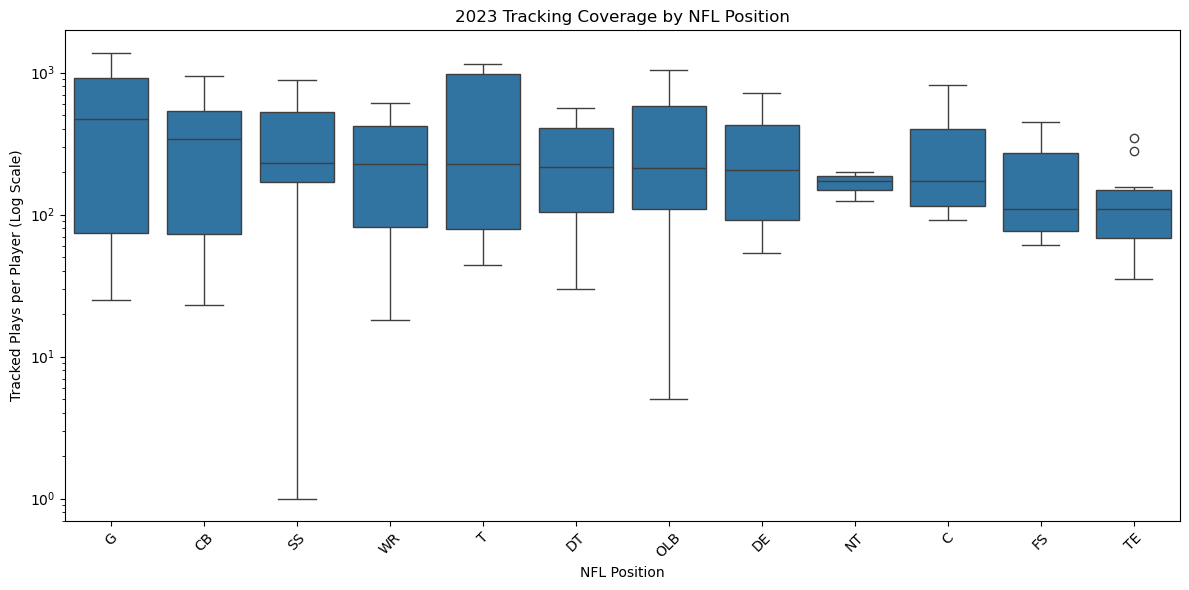

In [81]:
#Quick plot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=coverage_by_position_2023,
    x="nfl_position",
    y="plays",
    order=coverage_by_position_2023.groupby("nfl_position")["plays"].median().sort_values(ascending=False).index
)

plt.yscale("log")
plt.title("2023 Tracking Coverage by NFL Position")
plt.xlabel("NFL Position")
plt.ylabel("Tracked Plays per Player (Log Scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
